Part 1.1
# Libraries and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

df = pd.read_excel(
    "ebayAuctions.xlsx",
    sheet_name="eBay auctions"
)

df.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0,NaN
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0,NaN
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0,NaN
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0,NaN
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0,NaN


In [120]:
print("Dataset shape:", df.shape)

df.info()
display(df.describe(include="all"))

Dataset shape: (1975, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1975 entries, 0 to 1974
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   Currency      1972 non-null   object 
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1974 non-null   float64
 8   Unnamed: 8    1 non-null      float64
dtypes: float64(6), object(3)
memory usage: 139.0+ KB


,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
count,1972,1972,1972.000000,1972.000000,1972,1972.000000,1972.000000,1974.000000,1.000000
unique,18,3,NaN,NaN,7,NaN,NaN,NaN,NaN
top,Music/Movie/Game,US,NaN,NaN,Mon,NaN,NaN,NaN,NaN
freq,403,1292,NaN,NaN,548,NaN,NaN,NaN,NaN
mean,NaN,NaN,3560.238337,6.486308,NaN,36.449087,12.926268,1.905775,0.548535
std,NaN,NaN,5973.011033,2.052906,NaN,89.493858,38.856149,44.670344,NaN
min,NaN,NaN,0.000000,1.000000,NaN,0.010000,0.010000,0.000000,0.548535
25%,NaN,NaN,595.000000,5.000000,NaN,4.907500,1.230000,0.000000,0.548535
50%,NaN,NaN,1853.000000,7.000000,NaN,9.995000,4.500000,1.000000,0.548535
75%,NaN,NaN,3380.000000,7.000000,NaN,28.000000,9.990000,1.000000,0.548535


In [121]:
# Remove irrelevant column
df = df.drop("Unnamed: 8", axis=1)

# Remove extra rows
df = df[df["Competitive?"].isin([0, 1])]

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (1972, 8)


In [122]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)":
        df.isnull().mean() * 100
})

missing_summary

,Missing Count,Missing Percentage (%)
Category,0,0.0
Currency,0,0.0
sellerRating,0,0.0
Duration,0,0.0
endDay,0,0.0
ClosePrice,0,0.0
OpenPrice,0,0.0
Competitive?,0,0.0


In [123]:
df.duplicated().sum()
df[df.duplicated()]

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
54,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
55,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
56,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
72,Pottery/Glass,GBP,5292.0,7.0,Thu,1.78,1.78,0.0
79,Computer,EUR,3375.0,10.0,Thu,1.23,1.23,0.0
...,...,...,...,...,...,...,...,...
1925,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1926,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1927,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1928,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0


In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   Currency      1972 non-null   object 
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1972 non-null   float64
dtypes: float64(5), object(3)
memory usage: 123.4+ KB


In [125]:
df.describe()

,sellerRating,Duration,ClosePrice,OpenPrice,Competitive?
count,1972.000000,1972.000000,1972.000000,1972.000000,1972.000000
mean,3560.238337,6.486308,36.449087,12.926268,0.540568
std,5973.011033,2.052906,89.493858,38.856149,0.498478
min,0.000000,1.000000,0.010000,0.010000,0.000000
25%,595.000000,5.000000,4.907500,1.230000,0.000000
50%,1853.000000,7.000000,9.995000,4.500000,1.000000
75%,3380.000000,7.000000,28.000000,9.990000,1.000000
max,37727.000000,10.000000,999.000000,999.000000,1.000000


In [126]:
for col in ["Category", "Currency", "Duration",
            "endDay", "Competitive?"]:
    print(col, df[col].unique())

print("Negative seller ratings:",
      (df["sellerRating"] < 0).sum())

print("Non-positive opening prices:",
      (df["OpenPrice"] <= 0).sum())

print("Non-positive closing prices:",
      (df["ClosePrice"] <= 0).sum())

print("Closing price below opening price:",
      (df["ClosePrice"] < df["OpenPrice"]).sum())

Category ['Music/Movie/Game' 'SportingGoods' 'Business/Industrial' 'Automotive'
 'Collectibles' 'Home/Garden' 'Jewelry' 'Electronics' 'Coins/Stamps'
 'Pottery/Glass' 'Computer' 'Toys/Hobbies' 'Clothing/Accessories'
 'Antique/Art/Craft' 'Books' 'Health/Beauty' 'EverythingElse'
 'Photography']
Currency ['US' 'EUR' 'GBP']
Duration [ 7.  1.  5.  3. 10.]
endDay ['Mon' 'Fri' 'Sun' 'Tue' 'Wed' 'Thu' 'Sat']
Competitive? [0. 1.]
Negative seller ratings: 0
Non-positive opening prices: 0
Non-positive closing prices: 0
Closing price below opening price: 0


Part 1.2
# Data Processing and EDA

In [127]:
categorical_cols = [
    "Category", "Currency", "Duration", "endDay"
]

numerical_cols = [
    "sellerRating", "OpenPrice", "ClosePrice"
]

for col in categorical_cols:
    df[col] = df[col].astype("category")

df["Competitive?"] = df["Competitive?"].astype(int)

In [128]:
target = "Competitive?"

# Model 1: All available predictors
all_predictors = [
    "Category",
    "Currency",
    "sellerRating",
    "Duration",
    "endDay",
    "ClosePrice",
    "OpenPrice"
]

# Model 2 and k-NN: Predictors available before auction
practical_predictors = [
    col for col in all_predictors
    if col != "ClosePrice"
]

In [129]:
train_df, test_df = train_test_split(
    df,
    test_size=0.4,
    random_state=5,
    stratify=df[target]
)

y_train = train_df[target].copy()
y_test = test_df[target].copy()

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

Training set: (1183, 8)
Test set: (789, 8)


In [130]:
distribution = pd.DataFrame({
    "Full Dataset":
        df[target].value_counts(normalize=True),

    "Training Set":
        y_train.value_counts(normalize=True),

    "Test Set":
        y_test.value_counts(normalize=True)
}) * 100

display(distribution.round(2))

,Full Dataset,Training Set,Test Set
Competitive?,,,
1,54.06,54.02,54.12
0,45.94,45.98,45.88


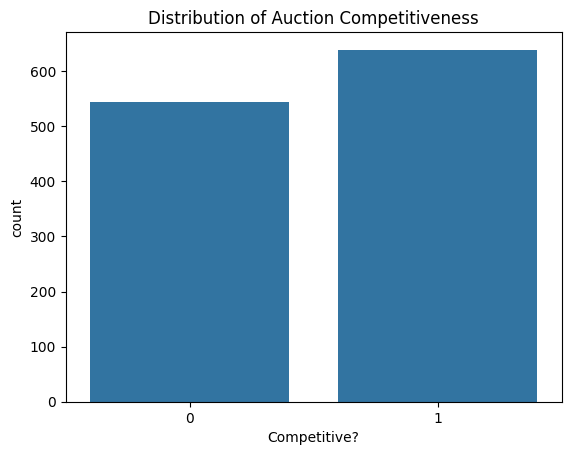

In [131]:
sns.countplot(data=train_df, x="Competitive?")
plt.title("Distribution of Auction Competitiveness")
plt.show()

In [132]:
train_df["Competitive?"].value_counts(normalize=True)

Competitive?
1    0.540152
0    0.459848
Name: proportion, dtype: float64

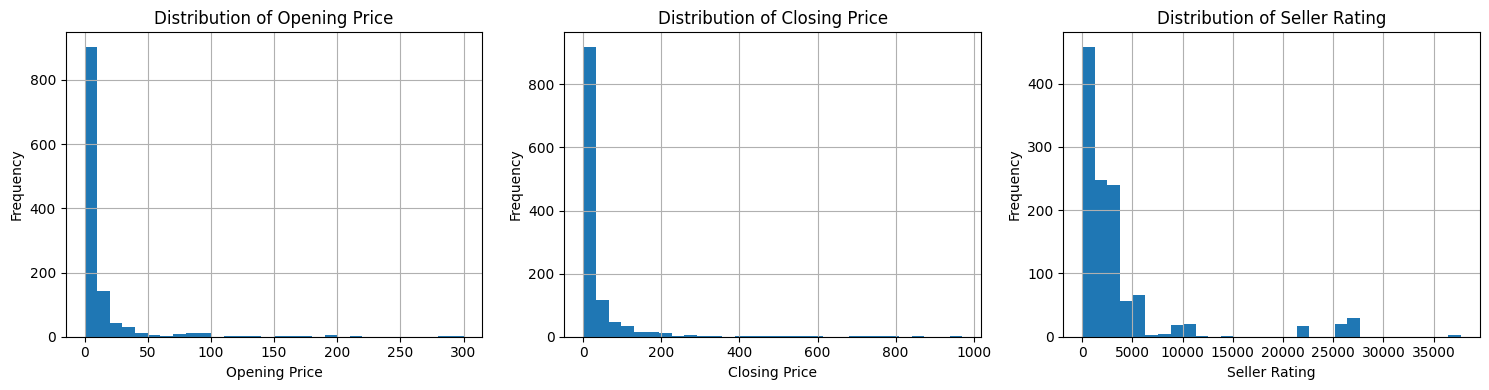

In [133]:
plt.figure(figsize=(15, 4))

# Opening Price
plt.subplot(1, 3, 1)
train_df["OpenPrice"].hist(bins=30)
plt.title("Distribution of Opening Price")
plt.xlabel("Opening Price")
plt.ylabel("Frequency")

# Closing Price
plt.subplot(1, 3, 2)
train_df["ClosePrice"].hist(bins=30)
plt.title("Distribution of Closing Price")
plt.xlabel("Closing Price")
plt.ylabel("Frequency")

# Seller Rating
plt.subplot(1, 3, 3)
train_df["sellerRating"].hist(bins=30)
plt.title("Distribution of Seller Rating")
plt.xlabel("Seller Rating")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

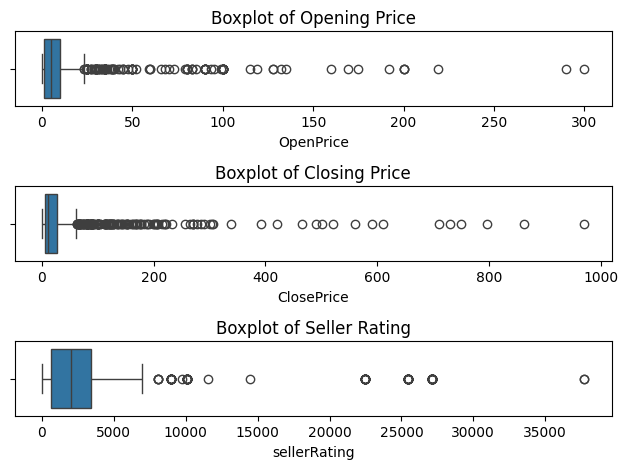

In [134]:
# Opening Price
plt.subplot(3, 1, 1)
sns.boxplot(data=train_df, x="OpenPrice")
plt.title("Boxplot of Opening Price")

# Closing Price
plt.subplot(3, 1, 2)
sns.boxplot(data=train_df, x="ClosePrice")
plt.title("Boxplot of Closing Price")

# Seller Rating
plt.subplot(3, 1, 3)
sns.boxplot(data=train_df, x="sellerRating")
plt.title("Boxplot of Seller Rating")

plt.tight_layout()
plt.show()

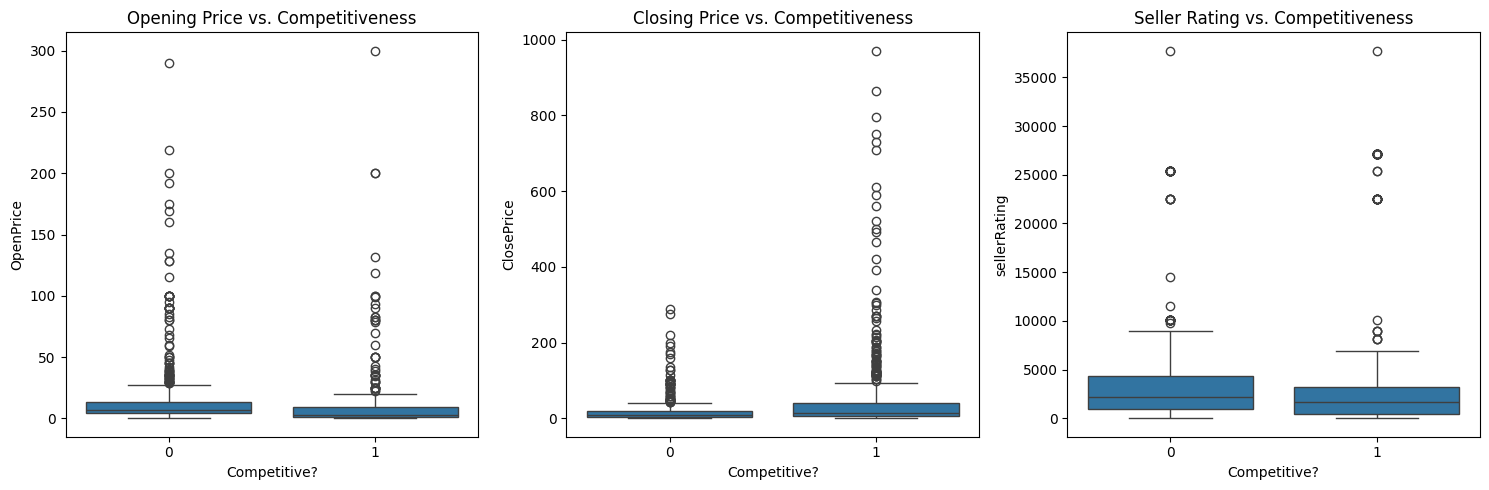

In [135]:
plt.figure(figsize=(15, 5))

# Opening Price vs. Target
plt.subplot(1, 3, 1)
sns.boxplot(data=train_df, x="Competitive?", y="OpenPrice")
plt.title("Opening Price vs. Competitiveness")

# Closing Price vs. Target
plt.subplot(1, 3, 2)
sns.boxplot(data=train_df, x="Competitive?", y="ClosePrice")
plt.title("Closing Price vs. Competitiveness")

# Seller Rating vs. Target
plt.subplot(1, 3, 3)
sns.boxplot(data=train_df, x="Competitive?", y="sellerRating")
plt.title("Seller Rating vs. Competitiveness")

plt.tight_layout()
plt.show()

In [136]:
train_df.groupby("Competitive?")[numerical_cols].median()

,sellerRating,OpenPrice,ClosePrice
Competitive?,,,
0,2204.5,6.99,7.99
1,1647.0,2.45,14.13


/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3820700134.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby("Duration")["Competitive?"].mean().plot(kind="bar")
/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3820700134.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby("Currency")["Competitive?"].mean().plot(kind="bar")
/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3820700134.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False 

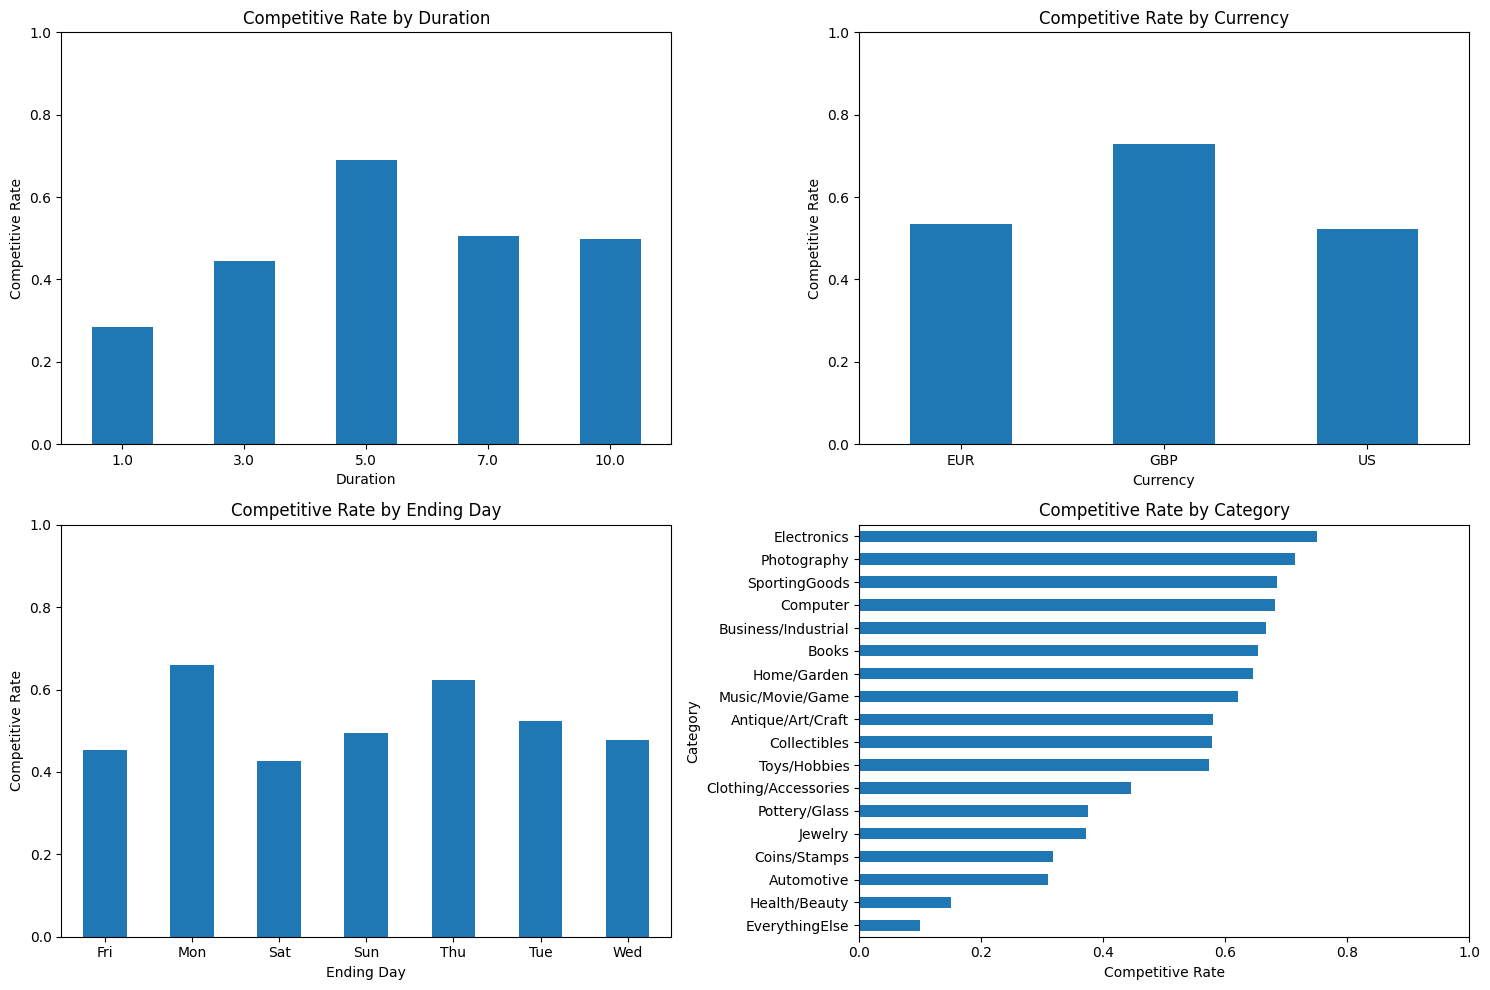

In [137]:
plt.figure(figsize=(15, 10))

# Duration
plt.subplot(2, 2, 1)
train_df.groupby("Duration")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Duration")
plt.ylabel("Competitive Rate")
plt.xlabel("Duration")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Currency
plt.subplot(2, 2, 2)
train_df.groupby("Currency")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Currency")
plt.ylabel("Competitive Rate")
plt.xlabel("Currency")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Ending Day
plt.subplot(2, 2, 3)
train_df.groupby("endDay")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Ending Day")
plt.ylabel("Competitive Rate")
plt.xlabel("Ending Day")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Category
plt.subplot(2, 2, 4)
train_df.groupby("Category")["Competitive?"].mean().sort_values().plot(kind="barh")
plt.title("Competitive Rate by Category")
plt.xlabel("Competitive Rate")
plt.ylabel("Category")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [138]:
print(train_df.groupby("Duration")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("Currency")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("endDay")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("Category")["Competitive?"].agg(["count", "mean"]))

          count      mean
Duration                 
1.0           7  0.285714
3.0         135  0.444444
5.0         283  0.689046
7.0         585  0.505983
10.0        173  0.497110
          count      mean
Currency                 
EUR         303  0.534653
GBP          85  0.729412
US          795  0.522013
        count      mean
endDay                 
Fri       170  0.452941
Mon       347  0.659942
Sat       202  0.425743
Sun       198  0.494949
Thu       117  0.623932
Tue       105  0.523810
Wed        44  0.477273
                      count      mean
Category                             
Antique/Art/Craft       112  0.580357
Automotive              113  0.309735
Books                    26  0.653846
Business/Industrial      12  0.666667
Clothing/Accessories     74  0.445946
Coins/Stamps             22  0.318182
Collectibles            128  0.578125
Computer                 22  0.681818
Electronics              36  0.750000
EverythingElse           10  0.100000
Health/Beauty   

/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/4215389748.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(train_df.groupby("Duration")["Competitive?"].agg(["count", "mean"]))
/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/4215389748.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(train_df.groupby("Currency")["Competitive?"].agg(["count", "mean"]))
/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/4215389748.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass obser

In [139]:
numerical_cols = ["OpenPrice", "ClosePrice", "sellerRating"]

corr = train_df[numerical_cols + [target]].corr()

corr

,OpenPrice,ClosePrice,sellerRating,Competitive?
OpenPrice,1.000000,0.354618,-0.043711,-0.155456
ClosePrice,0.354618,1.000000,0.013774,0.183881
sellerRating,-0.043711,0.013774,1.000000,-0.026347
Competitive?,-0.155456,0.183881,-0.026347,1.000000


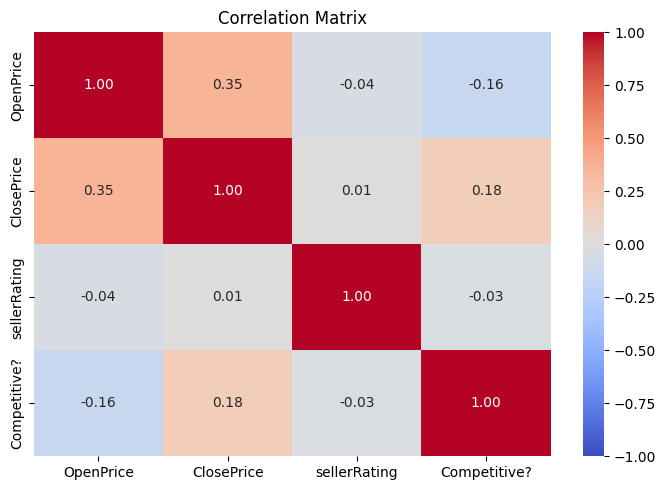

In [140]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

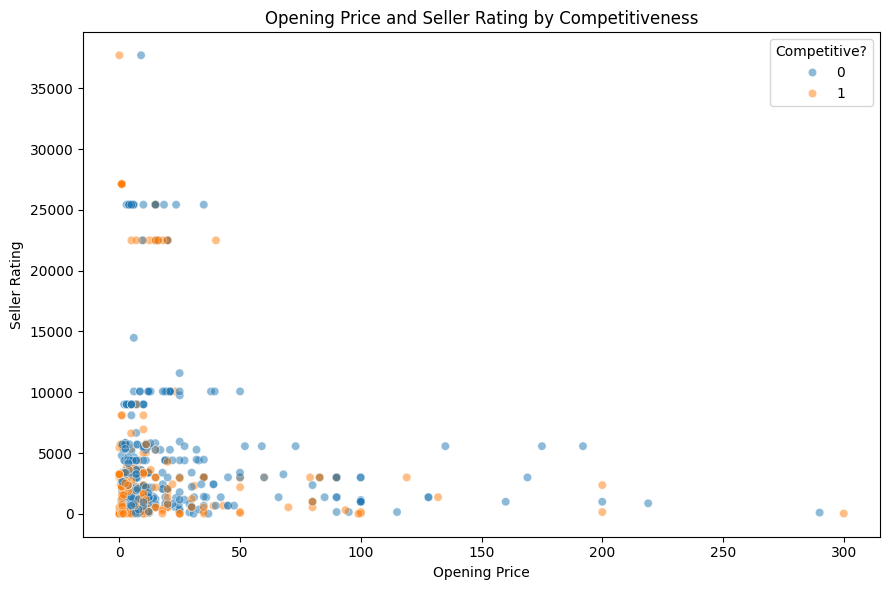

In [141]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=train_df,
    x="OpenPrice",
    y="sellerRating",
    hue="Competitive?",
    alpha=0.5
)

plt.title("Opening Price and Seller Rating by Competitiveness")
plt.xlabel("Opening Price")
plt.ylabel("Seller Rating")
plt.tight_layout()
plt.show()

Part 1.3
# Encoding and scaling

In [142]:
categorical_cols = [
    "Category",
    "Currency",
    "Duration",
    "endDay"
]

train_encoded = pd.get_dummies(
    train_df,
    columns=categorical_cols,
    dtype=int
)

train_encoded.head()

,sellerRating,ClosePrice,OpenPrice,Competitive?,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,...,Duration_5.0,Duration_7.0,Duration_10.0,endDay_Fri,endDay_Mon,endDay_Sat,endDay_Sun,endDay_Thu,endDay_Tue,endDay_Wed
891,215.0,1.77,1.77,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
788,632.0,8.91,8.91,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
1944,1364.0,135.00,132.00,1,0,1,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
945,1634.0,7.37,7.37,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
338,1179.0,49.79,1.23,1,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0


In [143]:
test_encoded = pd.get_dummies(
    test_df,
    columns=categorical_cols,
    dtype=int
)

test_encoded.head()

,sellerRating,ClosePrice,OpenPrice,Competitive?,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,...,Duration_5.0,Duration_7.0,Duration_10.0,endDay_Fri,endDay_Mon,endDay_Sat,endDay_Sun,endDay_Thu,endDay_Tue,endDay_Wed
1359,3385.0,12.50,8.99,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1563,957.0,15.99,15.99,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
1379,41.0,3.69,1.23,1,0,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
65,5701.0,15.37,1.23,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
695,3385.0,5.50,2.99,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0


In [144]:
# Ensure that the test set has the same columns as the training set
test_encoded = test_encoded.reindex(
    columns=train_encoded.columns,
    fill_value=0
)

print("Encoded training set:", train_encoded.shape)
print("Encoded testing set:", test_encoded.shape)
train_encoded.columns

Encoded training set: (1183, 37)
Encoded testing set: (789, 37)


Index(['sellerRating', 'ClosePrice', 'OpenPrice', 'Competitive?',
       'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books',
       'Category_Business/Industrial', 'Category_Clothing/Accessories',
       'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer',
       'Category_Electronics', 'Category_EverythingElse',
       'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry',
       'Category_Music/Movie/Game', 'Category_Photography',
       'Category_Pottery/Glass', 'Category_SportingGoods',
       'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US',
       'Duration_1.0', 'Duration_3.0', 'Duration_5.0', 'Duration_7.0',
       'Duration_10.0', 'endDay_Fri', 'endDay_Mon', 'endDay_Sat', 'endDay_Sun',
       'endDay_Thu', 'endDay_Tue', 'endDay_Wed'],
      dtype='object')

Part 1.4
# Prepare Data for Classification Trees

In [145]:
# Initial Classification Model: All available predictors

X_train = train_encoded.drop("Competitive?", axis=1)
y_train = train_encoded["Competitive?"]

X_test = test_encoded.drop("Competitive?", axis=1)
y_test = test_encoded["Competitive?"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1183, 36)
X_test: (789, 36)
y_train: (1183,)
y_test: (789,)


In [146]:
# Practical Classification Model: Predictors available before auction
X_train_practical = X_train.drop("ClosePrice", axis=1)

X_test_practical = X_test.drop("ClosePrice", axis=1)

print("Practical training set:", X_train_practical.shape)
print("Practical testing set:", X_test_practical.shape)

Practical training set: (1183, 35)
Practical testing set: (789, 35)


# Part 2: Classification Tree Using All Predictors

## 2.1 Model Training

In [147]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

tree_all = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=50,
    random_state=5
)

tree_all.fit(X_train, y_train)

DecisionTreeClassifier(min_samples_leaf=50, random_state=5)

In [148]:
print("Tree depth:", tree_all.get_depth())
print("Number of terminal nodes:", tree_all.get_n_leaves())
print("Training accuracy:", tree_all.score(X_train, y_train))
print("Test accuracy:", tree_all.score(X_test, y_test))

Tree depth: 7
Number of terminal nodes: 16
Training accuracy: 0.8250211327134404
Test accuracy: 0.8326996197718631


## 2.2 Decision Tree Visualization

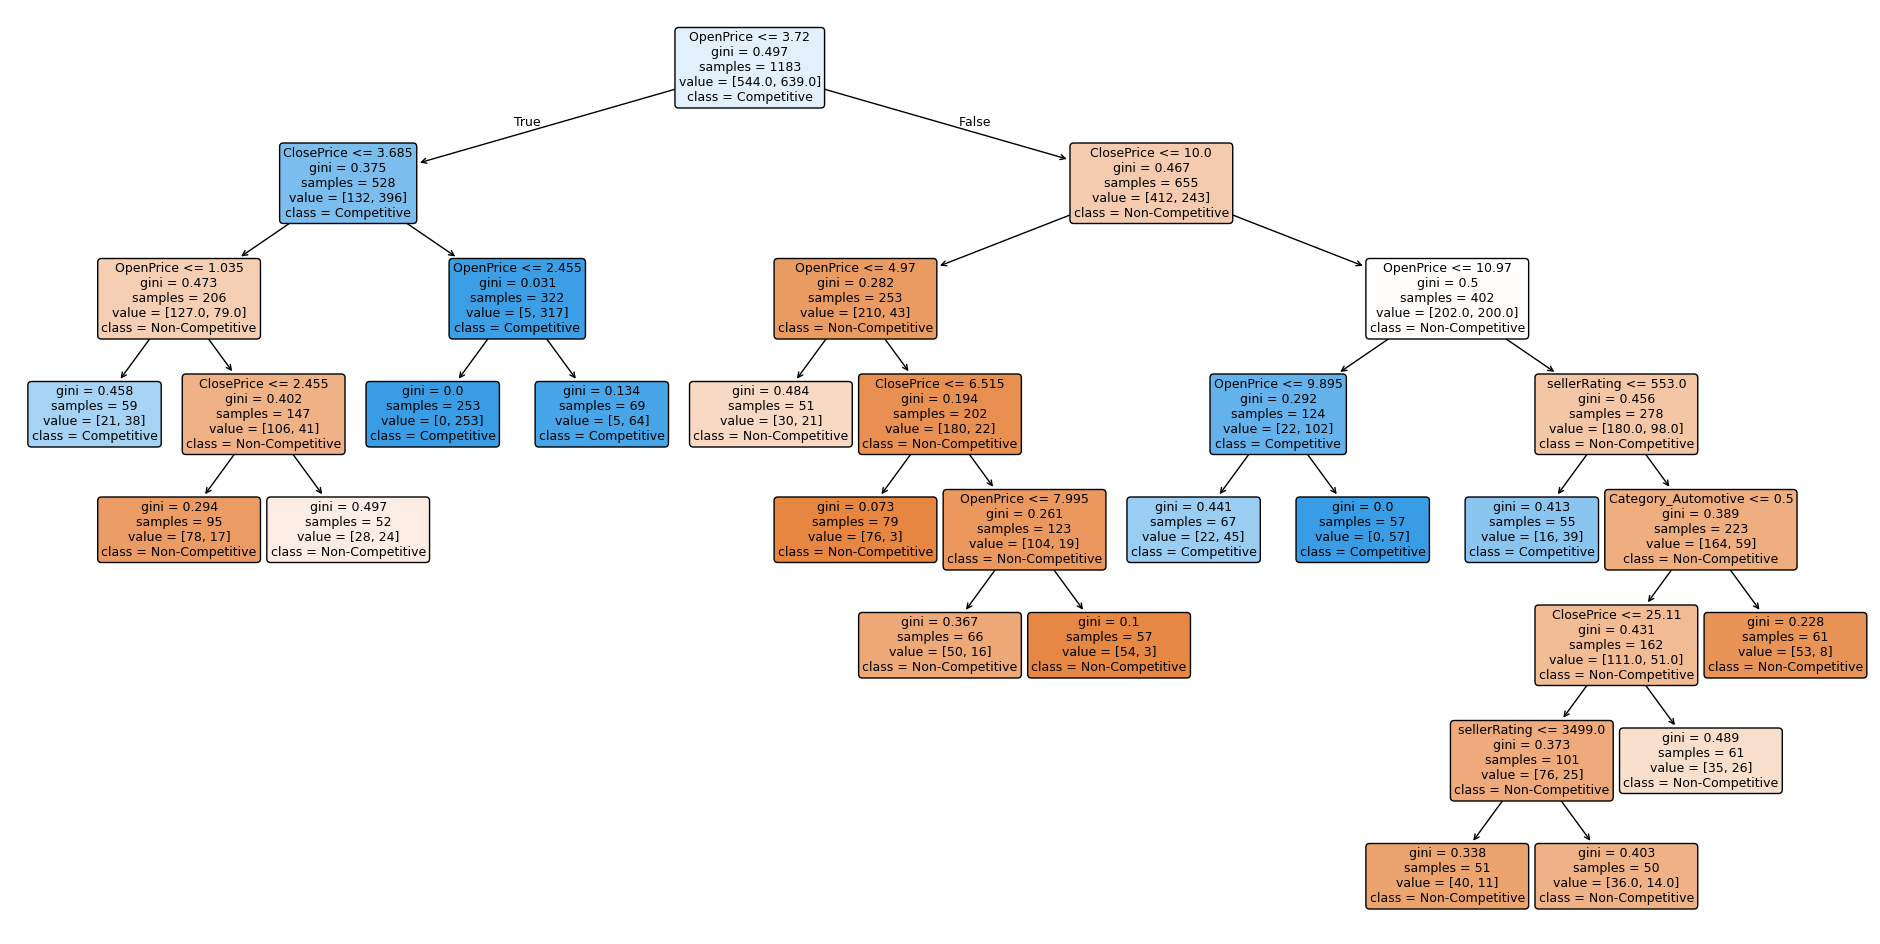

In [149]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_all,
    feature_names=X_train.columns,
    class_names=["Non-Competitive", "Competitive"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

## 2.3 Decision Rules

In [150]:
rules_all = export_text(
    tree_all,
    feature_names=list(X_train.columns)
)

print(rules_all)

|--- OpenPrice <= 3.72
|   |--- ClosePrice <= 3.69
|   |   |--- OpenPrice <= 1.04
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  1.04
|   |   |   |--- ClosePrice <= 2.46
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  2.46
|   |   |   |   |--- class: 0
|   |--- ClosePrice >  3.69
|   |   |--- OpenPrice <= 2.46
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  2.46
|   |   |   |--- class: 1
|--- OpenPrice >  3.72
|   |--- ClosePrice <= 10.00
|   |   |--- OpenPrice <= 4.97
|   |   |   |--- class: 0
|   |   |--- OpenPrice >  4.97
|   |   |   |--- ClosePrice <= 6.52
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  6.52
|   |   |   |   |--- OpenPrice <= 7.99
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- OpenPrice >  7.99
|   |   |   |   |   |--- class: 0
|   |--- ClosePrice >  10.00
|   |   |--- OpenPrice <= 10.97
|   |   |   |--- OpenPrice <= 9.89
|   |   |   |   |--- class: 1
|   |   |   |--- OpenPrice >  9.89
|   |   |   |   |--- class: 1
|   |   

## 2.4 Feature Importance

In [151]:
importance_all = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_all.feature_importances_
}).sort_values("Importance", ascending=False)

importance_all

,Feature,Importance
2,OpenPrice,0.493732
1,ClosePrice,0.438348
0,sellerRating,0.058079
4,Category_Automotive,0.009841
34,endDay_Tue,0.000000
33,endDay_Thu,0.000000
32,endDay_Sun,0.000000
31,endDay_Sat,0.000000
30,endDay_Mon,0.000000
20,Category_Toys/Hobbies,0.000000


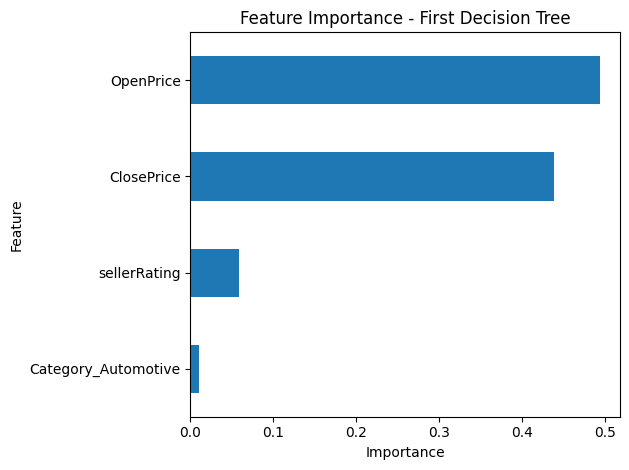

In [152]:
importance_all[importance_all["Importance"] > 0].plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Feature Importance - First Decision Tree")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 2.5 Predictor Reduction

In [153]:
unused_features = importance_all[importance_all["Importance"] == 0]

print("Number of unused predictors:", len(unused_features))
print(unused_features["Feature"].tolist())

Number of unused predictors: 32
['endDay_Tue', 'endDay_Thu', 'endDay_Sun', 'endDay_Sat', 'endDay_Mon', 'Category_Toys/Hobbies', 'Duration_10.0', 'Duration_7.0', 'Duration_5.0', 'Duration_3.0', 'Duration_1.0', 'Currency_US', 'Currency_GBP', 'Currency_EUR', 'endDay_Fri', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Photography', 'Category_Music/Movie/Game', 'Category_Jewelry', 'Category_Home/Garden', 'Category_Health/Beauty', 'Category_EverythingElse', 'Category_Electronics', 'Category_Computer', 'Category_Collectibles', 'Category_Coins/Stamps', 'Category_Clothing/Accessories', 'Category_Business/Industrial', 'Category_Books', 'Category_Antique/Art/Craft', 'endDay_Wed']


# Part 3: Classification Tree Using Practical Predictors

## 3.1 Model Training

For the purpose of prediction, closing price should be removed as it is not available at the time of a new auction.

In [154]:
# X_train_practical = X_train_practical.drop(unused_features["Feature"].tolist(), axis=1)
# X_test_practical = X_test_practical.drop(unused_features["Feature"].tolist(), axis=1)

In [155]:
tree_practical = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=50,
    random_state=5
)

tree_practical.fit(X_train_practical, y_train)

DecisionTreeClassifier(min_samples_leaf=50, random_state=5)

In [156]:
print("Tree depth:", tree_practical.get_depth())
print("Number of terminal nodes:", tree_practical.get_n_leaves())
print("Training accuracy:", tree_practical.score(X_train_practical, y_train))
print("Test accuracy:", tree_practical.score(X_test_practical, y_test))

Tree depth: 7
Number of terminal nodes: 17
Training accuracy: 0.7413355874894336
Test accuracy: 0.6818757921419518


## 3.2 Plot and Decision Rules

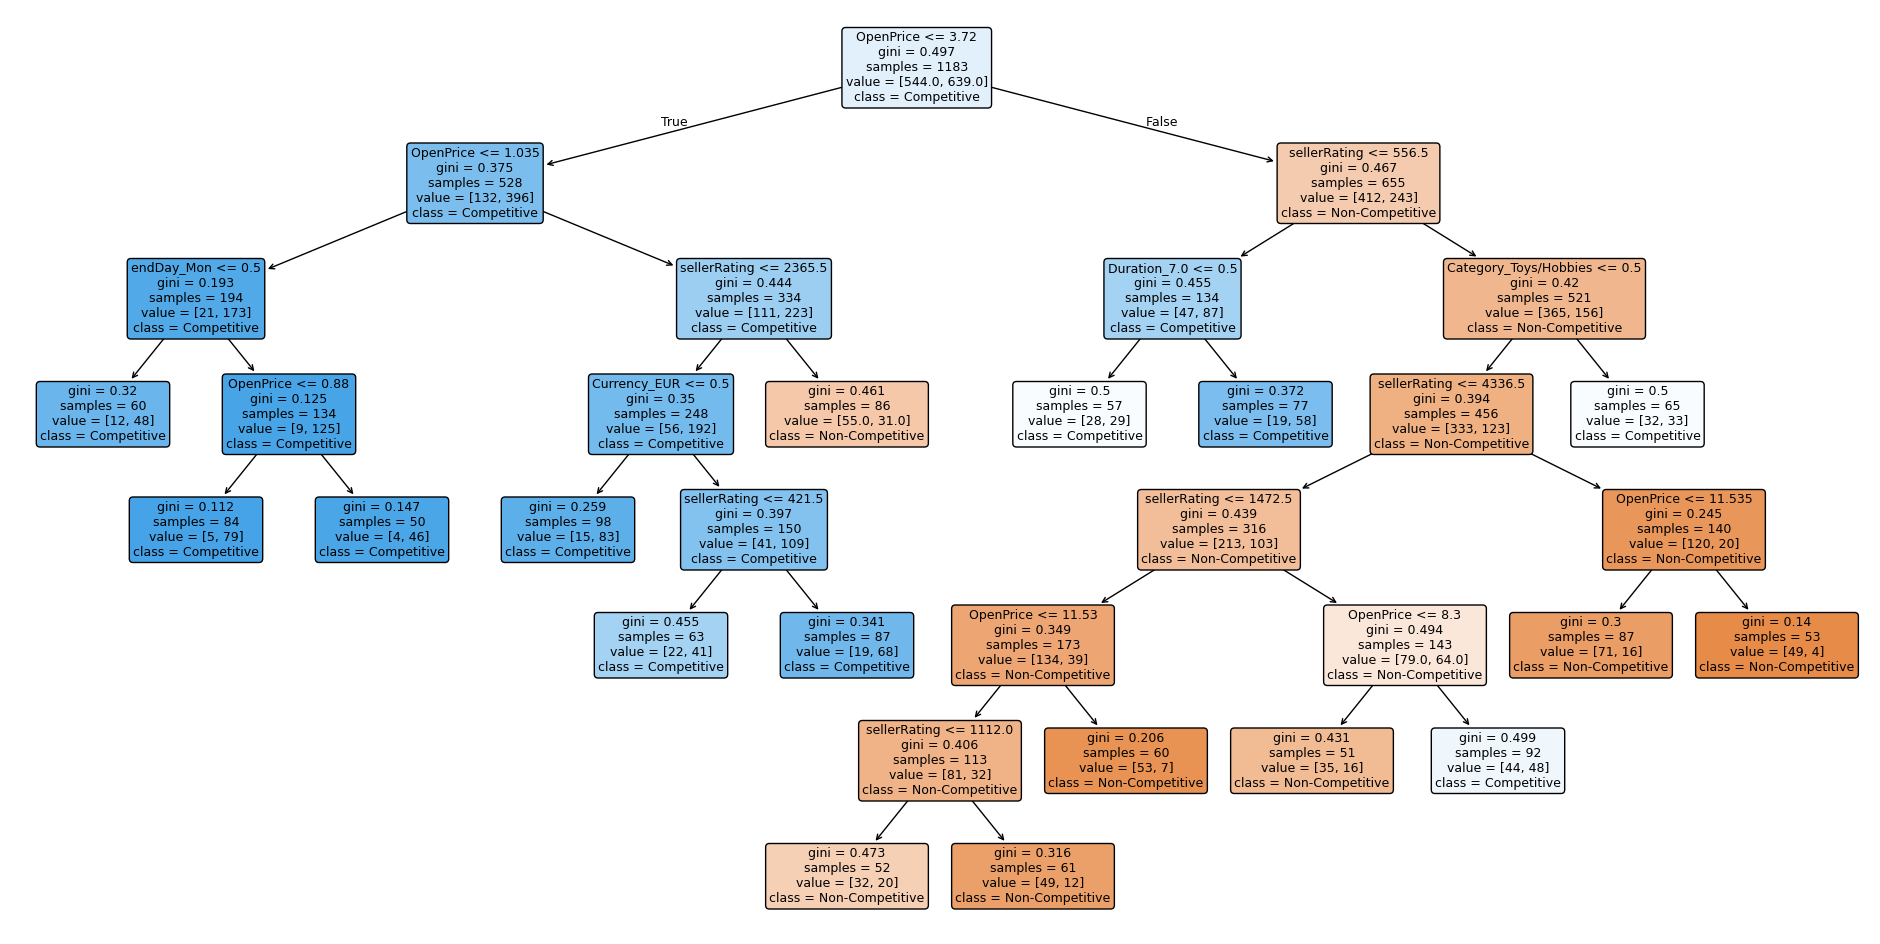

In [157]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_practical,
    feature_names=X_train_practical.columns,
    class_names=["Non-Competitive", "Competitive"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

In [158]:
rule_practical = export_text(
    tree_practical,
    feature_names=X_train_practical.columns)

print(rule_practical)

|--- OpenPrice <= 3.72
|   |--- OpenPrice <= 1.04
|   |   |--- endDay_Mon <= 0.50
|   |   |   |--- class: 1
|   |   |--- endDay_Mon >  0.50
|   |   |   |--- OpenPrice <= 0.88
|   |   |   |   |--- class: 1
|   |   |   |--- OpenPrice >  0.88
|   |   |   |   |--- class: 1
|   |--- OpenPrice >  1.04
|   |   |--- sellerRating <= 2365.50
|   |   |   |--- Currency_EUR <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Currency_EUR >  0.50
|   |   |   |   |--- sellerRating <= 421.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- sellerRating >  421.50
|   |   |   |   |   |--- class: 1
|   |   |--- sellerRating >  2365.50
|   |   |   |--- class: 0
|--- OpenPrice >  3.72
|   |--- sellerRating <= 556.50
|   |   |--- Duration_7.0 <= 0.50
|   |   |   |--- class: 1
|   |   |--- Duration_7.0 >  0.50
|   |   |   |--- class: 1
|   |--- sellerRating >  556.50
|   |   |--- Category_Toys/Hobbies <= 0.50
|   |   |   |--- sellerRating <= 4336.50
|   |   |   |   |--- sellerRating <= 1472.50
|   |

## 3.3 Feature Importance

In [159]:
importance_practical = pd.DataFrame({
    "Feature": X_train_practical.columns,
    "Importance": tree_practical.feature_importances_
}).sort_values("Importance", ascending=False)

importance_practical

,Feature,Importance
1,OpenPrice,0.564007
0,sellerRating,0.361242
19,Category_Toys/Hobbies,0.035580
26,Duration_7.0,0.021623
20,Currency_EUR,0.009470
29,endDay_Mon,0.008077
33,endDay_Tue,0.000000
32,endDay_Thu,0.000000
31,endDay_Sun,0.000000
30,endDay_Sat,0.000000


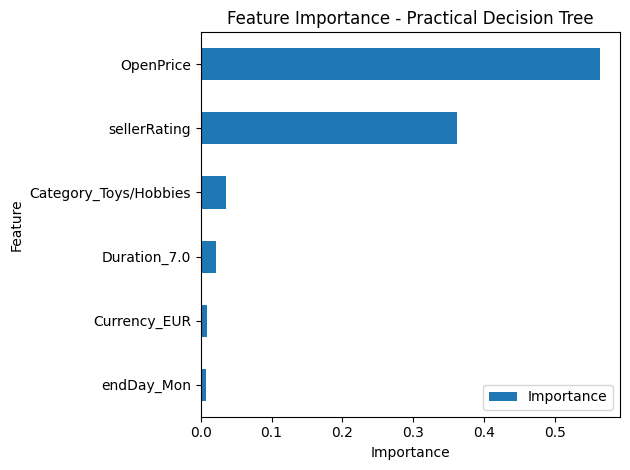

In [160]:
importance_practical[importance_practical["Importance"] > 0].plot(
    x="Feature",
    y="Importance",
    kind="barh"
)

plt.title("Feature Importance - Practical Decision Tree")
plt.xlabel("Importance")
plt.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Part 4: Visualization and Seller Recommendations

## 4.1 Scatter Plot with Decision Boundaries

In [161]:
from sklearn.tree import _tree

x_feature = "OpenPrice"
y_feature = "sellerRating"

tree_structure = tree_practical.tree_
feature_names = X_train_practical.columns.tolist()

split_thresholds = {
    x_feature: set(),
    y_feature: set()
}

for node in range(tree_structure.node_count):
    feature_index = tree_structure.feature[node]

    if feature_index != _tree.TREE_UNDEFINED:
        feature = feature_names[feature_index]

        if feature in split_thresholds:
            split_thresholds[feature].add(
                tree_structure.threshold[node]
            )

for feature, thresholds in split_thresholds.items():
    print(feature, sorted(round(t, 2) for t in thresholds))

OpenPrice [np.float64(0.88), np.float64(1.04), np.float64(3.72), np.float64(8.3), np.float64(11.53), np.float64(11.53)]
sellerRating [np.float64(421.5), np.float64(556.5), np.float64(1112.0), np.float64(1472.5), np.float64(2365.5), np.float64(4336.5)]


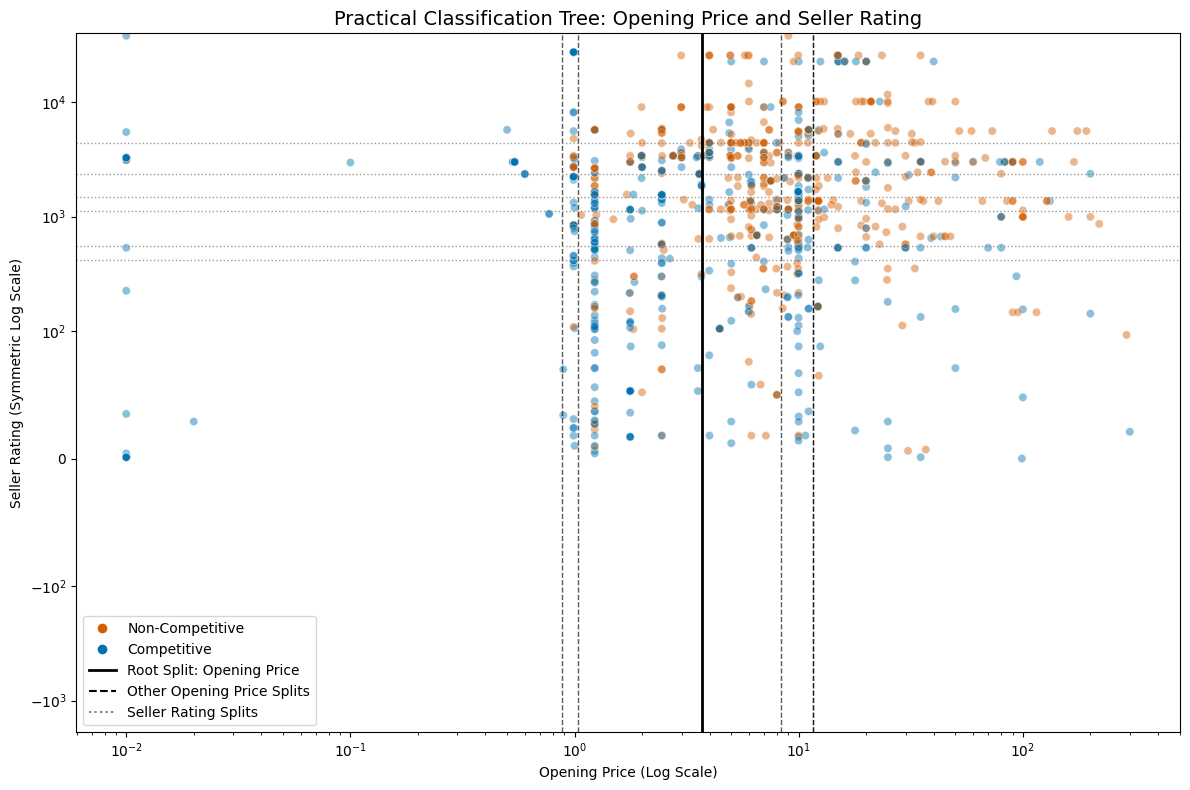

In [162]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=train_df,
    x=x_feature,
    y=y_feature,
    hue="Competitive?",
    palette={0: "#D55E00", 1: "#0072B2"},
    alpha=0.45,
    s=35,
    ax=ax
)

for threshold in sorted(split_thresholds[x_feature]):
    ax.axvline(
        x=threshold,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.65
    )


for threshold in sorted(split_thresholds[y_feature]):
    ax.axhline(
        y=threshold,
        color="gray",
        linestyle=":",
        linewidth=1,
        alpha=0.8
    )

ax.axvline(
    x=tree_structure.threshold[0],
    color="black",
    linewidth=2
)


ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=100)

ax.set_title(
    "Practical Classification Tree: "
    "Opening Price and Seller Rating",
    fontsize=14
)

ax.set_xlabel("Opening Price (Log Scale)")
ax.set_ylabel("Seller Rating (Symmetric Log Scale)")

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="#D55E00", markersize=8,
           label="Non-Competitive"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="#0072B2", markersize=8,
           label="Competitive"),
    Line2D([0], [0], color="black", linewidth=2,
           label="Root Split: Opening Price"),
    Line2D([0], [0], color="black", linestyle="--",
           label="Other Opening Price Splits"),
    Line2D([0], [0], color="gray", linestyle=":",
           label="Seller Rating Splits")
]

ax.legend(handles=legend_elements, loc="best")

plt.tight_layout()
plt.savefig("practical_tree_scatter.png",
            dpi=300, bbox_inches="tight")
plt.show()






## 4.3 Classification Table and Model Performance

In [163]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

y_train_pred_practical = tree_practical.predict(
    X_train_practical
)

y_test_pred_practical = tree_practical.predict(
    X_test_practical
)


cm_practical = confusion_matrix(
    y_test,
    y_test_pred_practical,
    labels=[0, 1]
)

classification_table = pd.DataFrame(
    cm_practical,
    index=[
        "Actual Non-Competitive",
        "Actual Competitive"
    ],
    columns=[
        "Predicted Non-Competitive",
        "Predicted Competitive"
    ]
)

display(classification_table)

print(classification_report(
    y_test,
    y_test_pred_practical,
    target_names=[
        "Non-Competitive",
        "Competitive"
    ],
    digits=4
))

,Predicted Non-Competitive,Predicted Competitive
Actual Non-Competitive,190,172
Actual Competitive,79,348


                 precision    recall  f1-score   support

Non-Competitive     0.7063    0.5249    0.6022       362
    Competitive     0.6692    0.8150    0.7350       427

       accuracy                         0.6819       789
      macro avg     0.6878    0.6699    0.6686       789
   weighted avg     0.6862    0.6819    0.6741       789



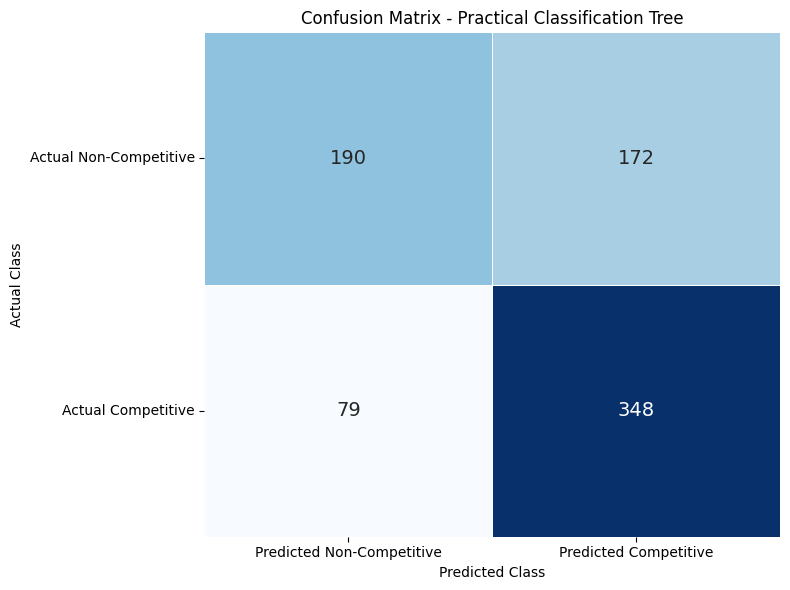

In [164]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    classification_table,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=0.5,
    annot_kws={"size": 14}
)

plt.title(
    "Confusion Matrix - Practical Classification Tree"
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "practical_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [165]:
tn, fp, fn, tp = cm_practical.ravel()

baseline_accuracy = y_test.value_counts(
    normalize=True
).max()

performance_practical = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Baseline Accuracy",
        "Accuracy Improvement",
        "Precision",
        "Recall (Sensitivity)",
        "Specificity",
        "F1 Score",
        "Balanced Accuracy"
    ],
    "Value": [
        accuracy_score(
            y_train, y_train_pred_practical
        ),
        accuracy_score(
            y_test, y_test_pred_practical
        ),
        baseline_accuracy,
        accuracy_score(
            y_test, y_test_pred_practical
        ) - baseline_accuracy,
        precision_score(
            y_test, y_test_pred_practical
        ),
        recall_score(
            y_test, y_test_pred_practical
        ),
        tn / (tn + fp),
        f1_score(
            y_test, y_test_pred_practical
        ),
        balanced_accuracy_score(
            y_test, y_test_pred_practical
        )
    ]
})

performance_practical["Percentage"] = (
    performance_practical["Value"] * 100
).round(2)

display(performance_practical)

,Metric,Value,Percentage
0,Training Accuracy,0.741336,74.13
1,Testing Accuracy,0.681876,68.19
2,Baseline Accuracy,0.541191,54.12
3,Accuracy Improvement,0.140684,14.07
4,Precision,0.669231,66.92
5,Recall (Sensitivity),0.814988,81.50
6,Specificity,0.524862,52.49
7,F1 Score,0.734952,73.50
8,Balanced Accuracy,0.669925,66.99


## 4.4 Relationship Between Seller-Controlled Settings and Auction Competitiveness

In [166]:
price_summary = train_df.groupby("Competitive?")["OpenPrice"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(price_summary.round(2))

,count,mean,median,std,min,max
Competitive?,,,,,,
0,544,16.56,6.99,30.04,0.01,290.0
1,639,8.38,2.45,21.81,0.01,300.0


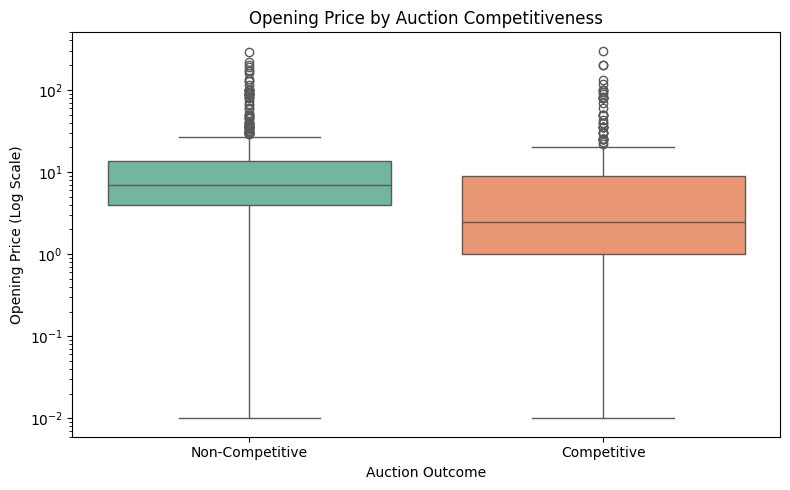

In [167]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Competitive?",
    y="OpenPrice",
    hue="Competitive?",
    palette="Set2",
    legend=False
)

plt.yscale("log")
plt.xticks([0, 1], ["Non-Competitive", "Competitive"])
plt.xlabel("Auction Outcome")
plt.ylabel("Opening Price (Log Scale)")
plt.title("Opening Price by Auction Competitiveness")

plt.tight_layout()
plt.show()

In [168]:
seller_settings = ["Duration", "endDay", "Currency"]

seller_summary = {}

for variable in seller_settings:

    summary = train_df.groupby(variable)["Competitive?"].agg(
        Total_Auctions="count",
        Competitive_Auctions="sum",
        Competitive_Rate="mean"
    )

    summary["Competitive_Rate"] *= 100

    summary = summary.sort_values(
        "Competitive_Rate",
        ascending=False
    )

    seller_summary[variable] = summary

    print(f"\nCompetitive Rate by {variable}")
    display(summary.round(2))


Competitive Rate by Duration


/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3031952652.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = train_df.groupby(variable)["Competitive?"].agg(


,Total_Auctions,Competitive_Auctions,Competitive_Rate
Duration,,,
5.0,283,195,68.90
7.0,585,296,50.60
10.0,173,86,49.71
3.0,135,60,44.44
1.0,7,2,28.57



Competitive Rate by endDay


/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3031952652.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = train_df.groupby(variable)["Competitive?"].agg(


,Total_Auctions,Competitive_Auctions,Competitive_Rate
endDay,,,
Mon,347,229,65.99
Thu,117,73,62.39
Tue,105,55,52.38
Sun,198,98,49.49
Wed,44,21,47.73
Fri,170,77,45.29
Sat,202,86,42.57



Competitive Rate by Currency


/var/folders/qk/4y68v1vj3ws6wcyk1vqq5xbc0000gn/T/ipykernel_20217/3031952652.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = train_df.groupby(variable)["Competitive?"].agg(


,Total_Auctions,Competitive_Auctions,Competitive_Rate
Currency,,,
GBP,85,62,72.94
EUR,303,162,53.47
US,795,415,52.20


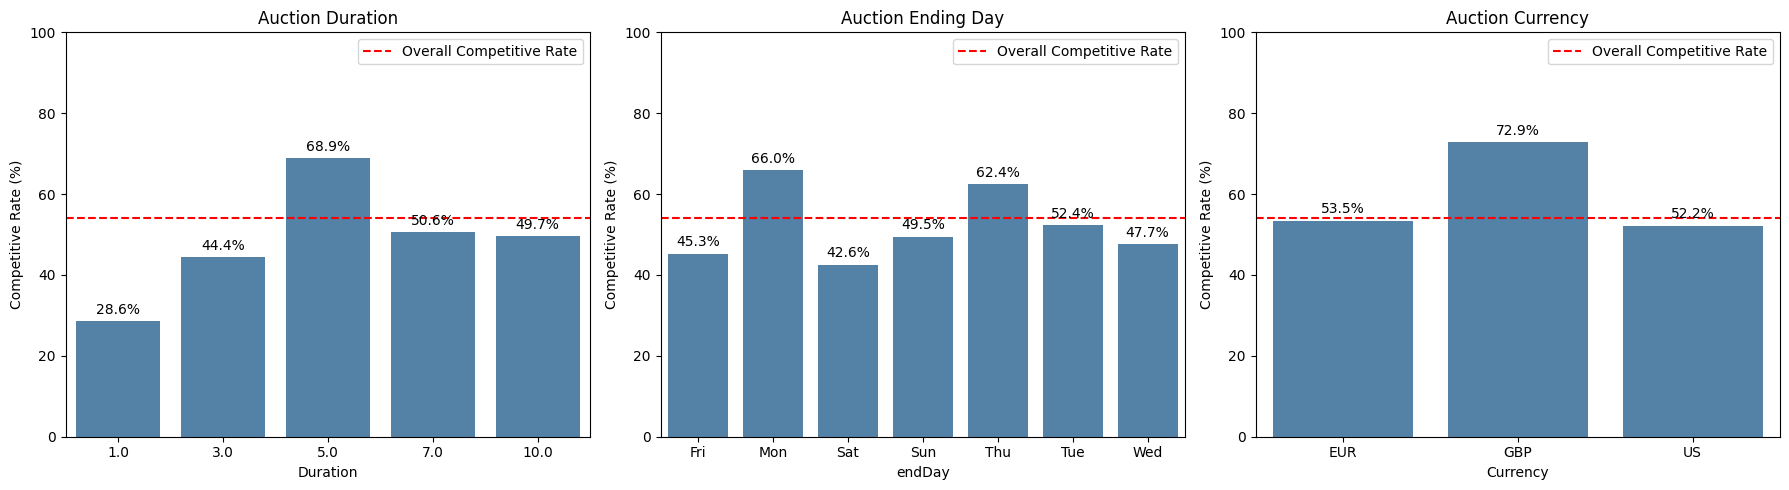

In [169]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

titles = {
    "Duration": "Auction Duration",
    "endDay": "Auction Ending Day",
    "Currency": "Auction Currency"
}

overall_rate = train_df["Competitive?"].mean() * 100

for ax, variable in zip(axes, seller_settings):

    summary = seller_summary[variable].reset_index()

    sns.barplot(
        data=summary,
        x=variable,
        y="Competitive_Rate",
        color="steelblue",
        ax=ax
    )

    ax.axhline(
        overall_rate,
        color="red",
        linestyle="--",
        label="Overall Competitive Rate"
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

    ax.set_title(titles[variable])
    ax.set_xlabel(variable)
    ax.set_ylabel("Competitive Rate (%)")
    ax.set_ylim(0, 100)
    ax.legend()

plt.tight_layout()

plt.savefig(
    "seller_settings_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [170]:
feature_importance = pd.Series(
    tree_practical.feature_importances_,
    index=X_train_practical.columns
)

seller_importance = pd.Series({
    "Opening Price": feature_importance.get("OpenPrice", 0),

    "Duration": feature_importance[
        feature_importance.index.str.startswith("Duration")
    ].sum(),

    "Ending Day": feature_importance[
        feature_importance.index.str.startswith("endDay")
    ].sum(),

    "Currency": feature_importance[
        feature_importance.index.str.startswith("Currency")
    ].sum()
})

seller_importance = (
    seller_importance * 100
).sort_values(ascending=False)

display(
    seller_importance.round(2).to_frame("Importance (%)")
)

,Importance (%)
Opening Price,56.40
Duration,2.16
Currency,0.95
Ending Day,0.81
